In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../pliki/airline-passengers.csv')
df.head()

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Month       144 non-null    str  
 1   Passengers  144 non-null    int64
dtypes: int64(1), str(1)
memory usage: 2.4 KB


### średnia

In [4]:
df["Passengers"].mean()

np.float64(280.2986111111111)

### maksimum

In [5]:
df["Passengers"].max()

np.int64(622)

### minimum

In [6]:
df["Passengers"].min()

np.int64(104)

### wariancja

In [7]:
df["Passengers"].var()

np.float64(14391.9172008547)

### odchylenie standardowe

In [ ]:
df["Passengers"].std()

### mediana

In [8]:
df["Passengers"].median()

np.float64(265.5)

### kwartyle

In [9]:
df["Passengers"].quantile([0.25, 0.5, 0.75])

0.25    180.0
0.50    265.5
0.75    360.5
Name: Passengers, dtype: float64

### średnia krocząca

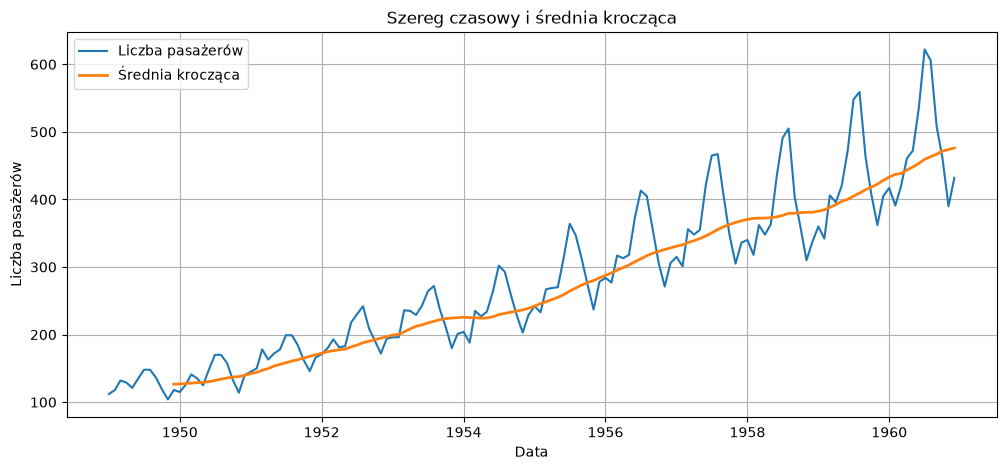

In [15]:
# Konwersja dat na format datetime
df["Month"] = pd.to_datetime(df["Month"])

rolling_mean = df["Passengers"].rolling(window=12).mean()  # obliczanie średniej
rolling_mean
plt.figure(figsize=(12, 5))
plt.plot(df["Month"], df["Passengers"], label="Liczba pasażerów")
plt.plot(df["Month"], rolling_mean, label="Średnia krocząca", linewidth=2)
plt.title("Szereg czasowy i średnia krocząca")
plt.xlabel("Data")
plt.ylabel("Liczba pasażerów")
plt.legend()
plt.grid(True)
plt.show()

### odchylenie standardowe kroczące

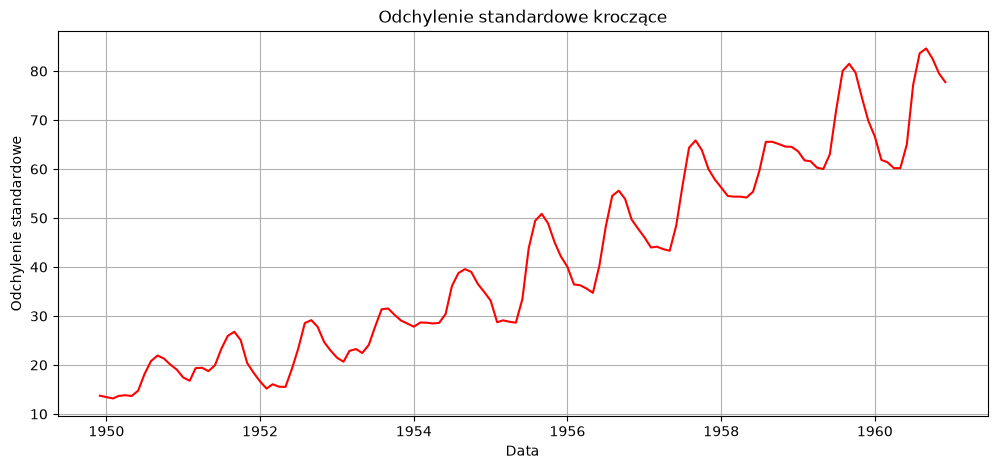

In [17]:
# Konwersja dat na format datetime
df["Month"] = pd.to_datetime(df["Month"])

rolling_std = df["Passengers"].rolling(window=12).std()
rolling_std
plt.figure(figsize=(12, 5))
plt.plot(df["Month"], rolling_std, color="red")
plt.title("Odchylenie standardowe kroczące")
plt.xlabel("Data")
plt.ylabel("Odchylenie standardowe")
plt.grid(True)
plt.show()

### transformata Fouriera

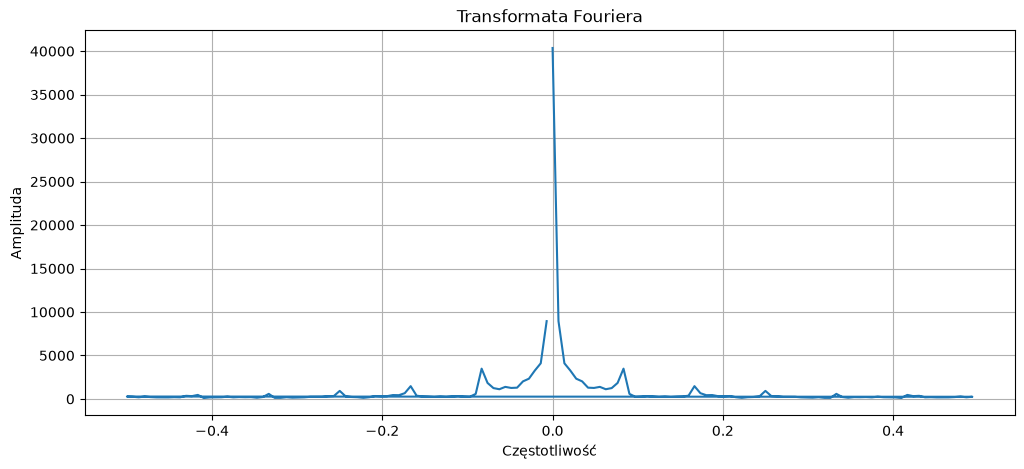

In [18]:
fft = np.fft.fft(df["Passengers"])
freq = np.fft.fftfreq(len(df))
plt.figure(figsize=(12, 5))
plt.plot(freq, np.abs(fft))
plt.title("Transformata Fouriera")
plt.xlabel("Częstotliwość")
plt.ylabel("Amplituda")
plt.grid(True)
plt.show()


### dekompozycja szeregu czasowego

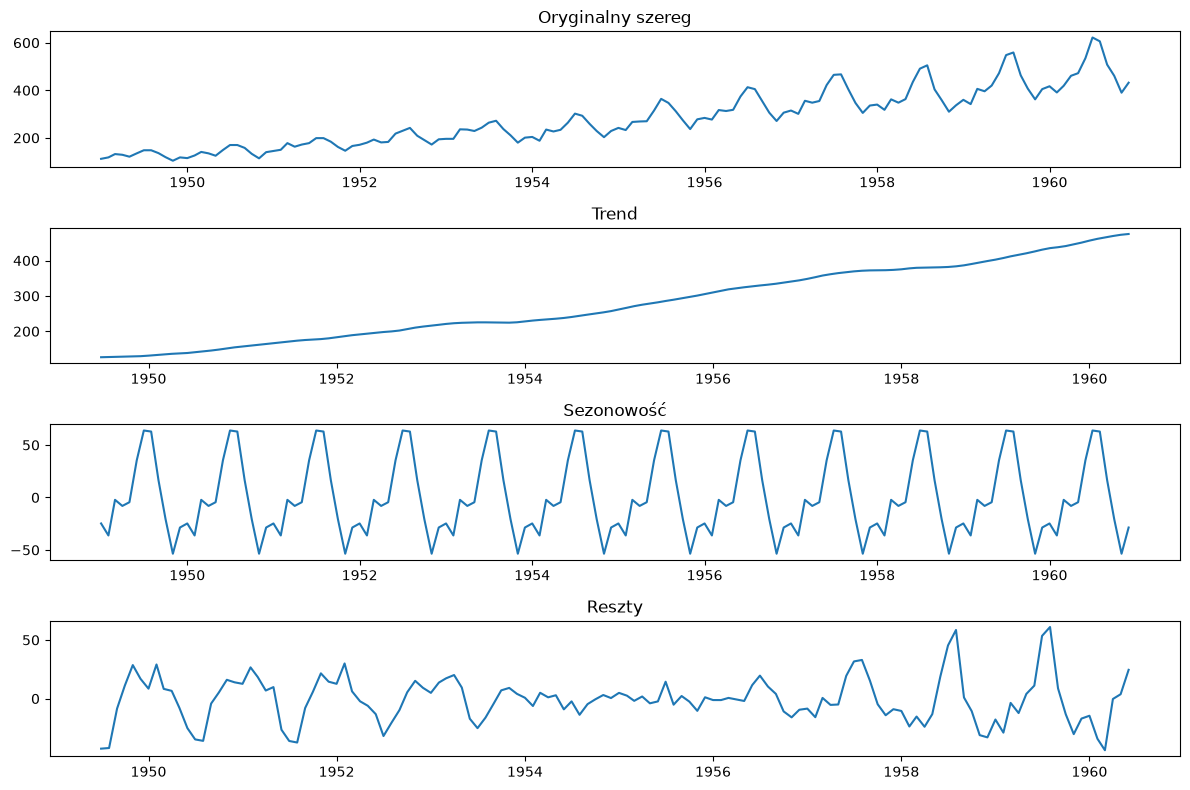

In [19]:
from statsmodels.tsa.seasonal import seasonal_decompose

df['Month'] = pd.to_datetime(df['Month'])
df['Passengers'] = pd.to_numeric(df['Passengers'])

df = df.set_index('Month')

decomposition = seasonal_decompose(df, model='additive', period=12)
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid
plt.figure(figsize=(12, 8))
plt.subplot(4, 1, 1)
plt.plot(df)
plt.title("Oryginalny szereg")
plt.subplot(4, 1, 2)
plt.plot(trend)
plt.title("Trend")
plt.subplot(4, 1, 3)
plt.plot(seasonal)
plt.title("Sezonowość")
plt.subplot(4, 1, 4)
plt.plot(residual)
plt.title("Reszty")
plt.tight_layout()
plt.show()